In [1]:
# pip install sqlalchemy

# Biblioteca para manipulação e análise de dados.
import pandas as pd
# Biblioteca para criação e personalização de gráficos.
import matplotlib.pyplot as plt
# Formatação de datas nos eixos dos gráficos.
import matplotlib.dates as mdates
# Formatação de valores e controle das marcações dos eixos.
from matplotlib.ticker import FuncFormatter, MaxNLocator
# Gerenciamento da conexão com o banco e execução de consultas SQL.
from sqlalchemy import create_engine, URL, text
# Exibição formatada de DataFrames no Jupyter Notebook.
from IPython.display import display
# Importação das configurações de conexão com o PostgreSQL.
from config import POSTGRES_CONFIG



url_conexao = URL.create(
    drivername="postgresql+psycopg2",
    username=POSTGRES_CONFIG["user"],
    password=POSTGRES_CONFIG["password"],
    host=POSTGRES_CONFIG["host"],
    port=POSTGRES_CONFIG["port"],
    database=POSTGRES_CONFIG["dbname"]
)

engine = create_engine(url_conexao)

query_silver_trajetos = """
SELECT *
FROM silver_trajetos;
"""

query_silver_embarques = """
SELECT *
FROM silver_embarques;
"""

query_silver_gastos = """
SELECT *
FROM silver_gastos;
"""

query_silver_deslocamentos = """
SELECT *
FROM silver_deslocamentos;
"""

with engine.connect() as conexao:
    df_trajetos = pd.read_sql_query(query_silver_trajetos, conexao)
    df_embarques = pd.read_sql_query(query_silver_embarques, conexao)
    df_gastos = pd.read_sql_query(query_silver_gastos, conexao)
    df_deslocamentos = pd.read_sql_query(query_silver_deslocamentos, conexao)


engine.dispose()

print("Consulta realizada com SQLAlchemy e pandas.")

Consulta realizada com SQLAlchemy e pandas.


In [2]:
df_gastos

,id_pagamento,id_viagem,num_proposta,nome_orgao_pagador,nome_ug_pagadora,tipo_pagamento,valor
0,1,20286869,000002/25,Universidade Federal do Paraná,UNIVERSIDADE FEDERAL DO PARANA,PASSAGEM,1271.77
1,2,20286869,000002/25,Universidade Federal do Paraná,UNIVERSIDADE FEDERAL DO PARANA,PASSAGEM,1272.97
2,3,20289421,000001/25,Comando do Exército,GABINETE DO COMANDANTE DO EXERCITO,PASSAGEM,4329.72
3,4,20289421,000001/25,Comando do Exército,GABINETE DO COMANDANTE DO EXERCITO,RESTITUIÇÃO,1240.09
4,5,20289650,000004/25,Comando do Exército,GABINETE DO COMANDANTE DO EXERCITO,RESTITUIÇÃO,1053.53
...,...,...,...,...,...,...,...
495,496,20536291,000422/25-11C,Fundo Nacional de Segurança Pública,FUNDO NACIONAL DE SEGURANCA PUBLICA - FNSP,PASSAGEM,1843.37
496,497,20536291,000422/25-11C,Fundo Nacional de Segurança Pública,FUNDO NACIONAL DE SEGURANCA PUBLICA - FNSP,PASSAGEM,413.69
497,498,20536291,000422/25-11C,Fundo Nacional de Segurança Pública,FUNDO NACIONAL DE SEGURANCA PUBLICA - FNSP,DIÁRIAS,6375.00
498,499,20536291,000422/25-11C,Fundo Nacional de Segurança Pública,FUNDO NACIONAL DE SEGURANCA PUBLICA - FNSP,DIÁRIAS,4781.25


In [2]:
# Reutiliza o padrão de conexão fornecido para executar consultas SELECT.
def consultar(query):
    with engine.connect() as conexao:
        return pd.read_sql_query(query, conexao)

# Formata os valores monetários no padrão brasileiro.
def formatar_reais(valor, posicao=None):
    return "R$ " + f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

# Ajusta os gráficos de barras horizontais: maior valor no topo.
def grafico_ranking(df, categoria, metrica, titulo, eixo_x, monetario=False):
    # Remove valores ausentes apenas da visualização, não da tabela de resultados.
    dados = df.dropna(subset=[metrica]).copy()
    if dados.empty:
        print("Não há dados válidos para gerar este gráfico.")
        return

    # Usa posições numéricas para evitar sobreposição de categorias repetidas.
    fig, ax = plt.subplots(figsize=(12, max(4, len(dados) * 0.48 + 1.5)))
    posicoes = range(len(dados))
    ax.barh(posicoes, dados[metrica])
    ax.set_yticks(list(posicoes), labels=dados[categoria])
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel(eixo_x)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    # Diferencia contagens inteiras de valores monetários.
    if monetario:
        ax.xaxis.set_major_formatter(FuncFormatter(formatar_reais))
    else:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout()
    plt.show()

Evolução mensal da quantidade de viagens

Pergunta de negócio: em quais meses há maior volume de viagens registradas?

,mes,qtd_viagens,valor_total,qtd_com_valor_total
0,2025-01-01,779,28755217.32,779
1,2025-02-01,155,709521.04,155
2,2025-03-01,36,140047.42,36
3,2025-04-01,16,34382.53,16
4,2025-05-01,10,31772.90,10
5,2025-06-01,4,6930.78,4


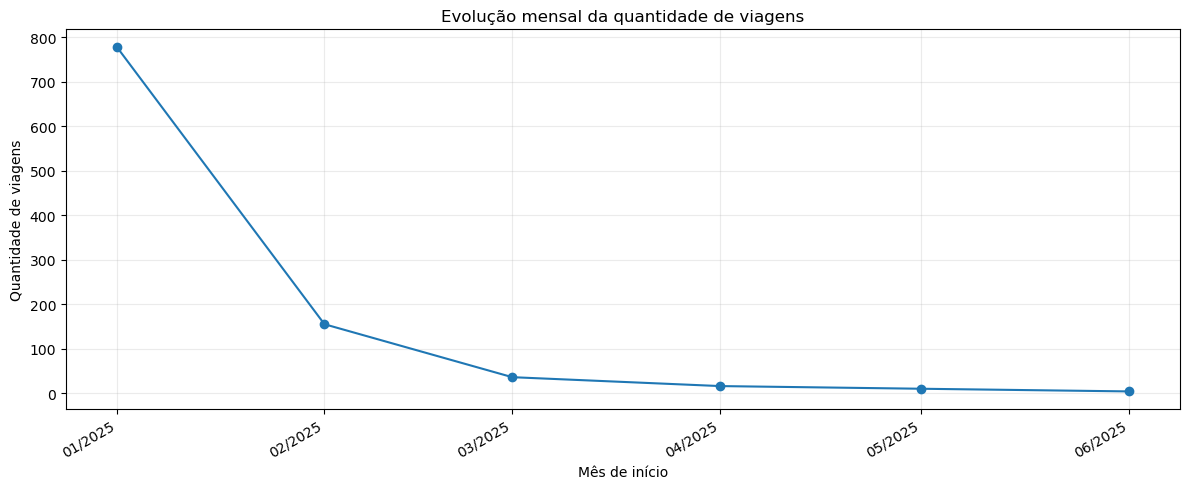

In [3]:
query = """
    SELECT
        DATE_TRUNC('month', data_inicio)::date AS mes, -- Mês de início da viagem.
        COUNT(*) AS qtd_viagens,                      -- Quantidade de viagens.
        SUM(valor_total) AS valor_total,              -- Soma dos valores conhecidos.
        COUNT(valor_total) AS qtd_com_valor_total      -- Cobertura do indicador financeiro.
    FROM silver_deslocamentos                         -- Uma linha por viagem.
    WHERE data_inicio IS NOT NULL                     -- Exclui datas ausentes.
    GROUP BY 1                                        -- Agrupa pelo mês.
    ORDER BY 1;                                       -- Ordena cronologicamente.
"""

# Executa a consulta e apresenta a tabela de resultados.
df_mensal = consultar(query)
display(df_mensal)

# Converte o mês para datetime e apresenta a evolução em um gráfico de linha.
if not df_mensal.empty:
    df_mensal["mes"] = pd.to_datetime(df_mensal["mes"])
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(df_mensal["mes"], df_mensal["qtd_viagens"], marker="o")
    ax.set_title("Evolução mensal da quantidade de viagens")
    ax.set_xlabel("Mês de início")
    ax.set_ylabel("Quantidade de viagens")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
else:
    print("Não há viagens com data de início para analisar.")

Ranking dos 10 órgãos superiores com maiores gastos

Pergunta de negócio: quais órgãos concentram os maiores valores de viagens?

,cod_orgao_superior,orgao,qtd_viagens,qtd_com_valor_total,gasto_total,gasto_medio
0,30000,Ministério da Justiça e Segurança Pública,238,238,26782013.97,112529.47
1,52000,Ministério da Defesa,522,522,1803917.85,3455.78
2,26000,Ministério da Educação,159,159,574435.13,3612.80
3,68000,Ministério de Portos e Aeroportos,16,16,104531.58,6533.22
4,25000,Ministério da Fazenda,13,13,103645.91,7972.76
5,24000,"Ministério da Ciência, Tecnologia e Inovação",7,7,55557.89,7936.84
6,-1,Sem informação,8,8,50548.06,6318.51
7,28000,"Ministério do Desenvolvimento, Indústria, Comé...",2,2,49793.28,24896.64
8,36000,Ministério da Saúde,5,5,45440.64,9088.13
9,35000,Ministério das Relações Exteriores,1,1,36792.46,36792.46


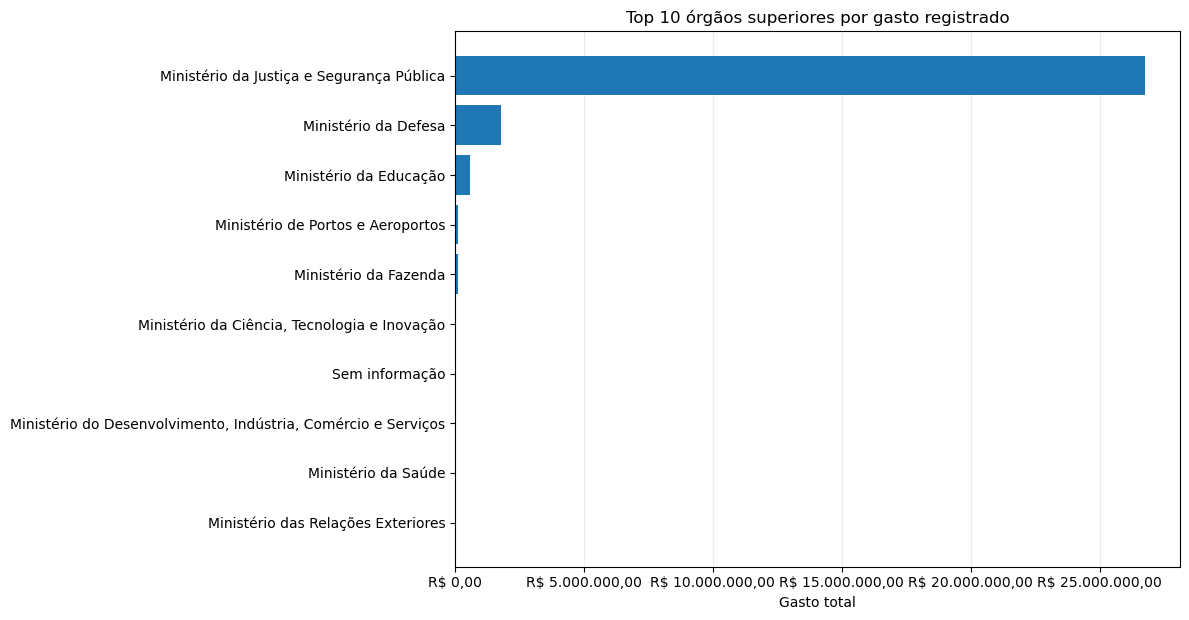

In [4]:
query = """
    SELECT
        cod_orgao_superior,                         -- Código do órgão superior.
        nome_orgao_superior AS orgao,                -- Nome do órgão superior.
        COUNT(*) AS qtd_viagens,                    -- Viagens vinculadas ao órgão.
        COUNT(valor_total) AS qtd_com_valor_total,    -- Viagens com valor informado.
        SUM(valor_total) AS gasto_total,             -- Total financeiro registrado.
        ROUND(AVG(valor_total), 2) AS gasto_medio    -- Média por viagem com valor conhecido.
    FROM silver_deslocamentos                       -- Base sem duplicação de viagens.
    GROUP BY cod_orgao_superior, nome_orgao_superior  -- Agrupa por órgão.
    HAVING COUNT(valor_total) > 0                    -- Mantém órgãos com valor conhecido.
    ORDER BY gasto_total DESC, orgao, cod_orgao_superior NULLS LAST
    LIMIT 10;                                       -- Seleciona os dez primeiros.
"""

# Carrega e exibe o ranking gerencial.
df_orgaos = consultar(query)
display(df_orgaos)

# Visualiza os órgãos ordenados pelo total de gastos.
grafico_ranking(df_orgaos, "orgao", "gasto_total",
                "Top 10 órgãos superiores por gasto registrado", "Gasto total", monetario=True)

Composição financeira das viagens

Pergunta de negócio: como os valores registrados se distribuem entre diárias, passagens, outros gastos e devoluções?

,componente,valor,qtd_com_valor
0,Diárias,26379035.54,1000
1,Passagens,3309159.68,1000
2,Outros gastos,92077.61,1000
3,Devoluções,102400.84,1000


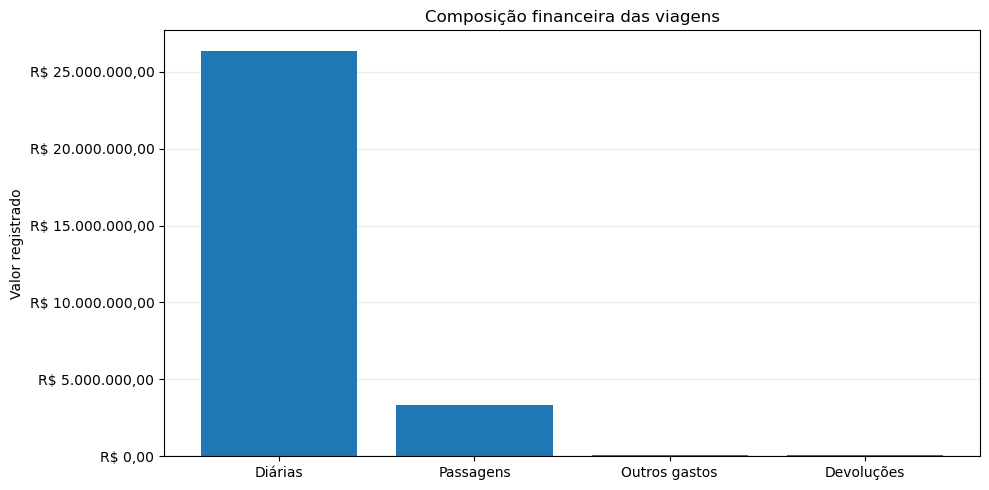

In [5]:
query = """
    SELECT
        SUM(valor_diarias) AS diarias,                 -- Total de diárias.
        SUM(valor_passagens) AS passagens,             -- Total de passagens.
        SUM(valor_outros_gastos) AS outros_gastos,     -- Total de outros gastos.
        SUM(valor_devolucao) AS devolucoes,            -- Devoluções com o sinal registrado.
        COUNT(valor_diarias) AS n_diarias,             -- Viagens com diárias informadas.
        COUNT(valor_passagens) AS n_passagens,         -- Viagens com passagens informadas.
        COUNT(valor_outros_gastos) AS n_outros_gastos, -- Viagens com outros gastos informados.
        COUNT(valor_devolucao) AS n_devolucoes         -- Viagens com devoluções informadas.
    FROM silver_deslocamentos;                       -- Soma cada componente na base principal.
"""

# Executa a consulta que retorna uma linha de totais.
df_componentes = consultar(query)

# Organiza os totais em linhas para facilitar a visualização no gráfico.
componentes = {"Diárias": "diarias", "Passagens": "passagens",
               "Outros gastos": "outros_gastos", "Devoluções": "devolucoes"}
df_composicao = pd.DataFrame([
    {"componente": nome,
     "valor": df_componentes.loc[0, coluna],
     "qtd_com_valor": df_componentes.loc[0, "n_" + coluna]}
    for nome, coluna in componentes.items()
])
df_composicao["valor"] = pd.to_numeric(df_composicao["valor"], errors="coerce")
display(df_composicao)

# Exibe apenas os componentes com valores conhecidos, preservando zeros e negativos.
dados = df_composicao.dropna(subset=["valor"])
if not dados.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(dados["componente"], dados["valor"])
    ax.set_title("Composição financeira das viagens")
    ax.set_ylabel("Valor registrado")
    ax.yaxis.set_major_formatter(FuncFormatter(formatar_reais))
    ax.axhline(0, linewidth=0.8)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print("Não há valores financeiros informados.")

As 10 UFs de destino com maior número de viagens
Pergunta de negócio: quais UFs são mais frequentes como destino dos trechos?

,uf_destino,qtd_viagens
0,DISTRITO FEDERAL,73
1,SÃO PAULO,43
2,MINAS GERAIS,40
3,RIO DE JANEIRO,35
4,MATO GROSSO DO SUL,11
5,PARANÁ,11
6,RIO GRANDE DO SUL,11
7,AMAZONAS,10
8,BAHIA,6
9,TOCANTINS,4


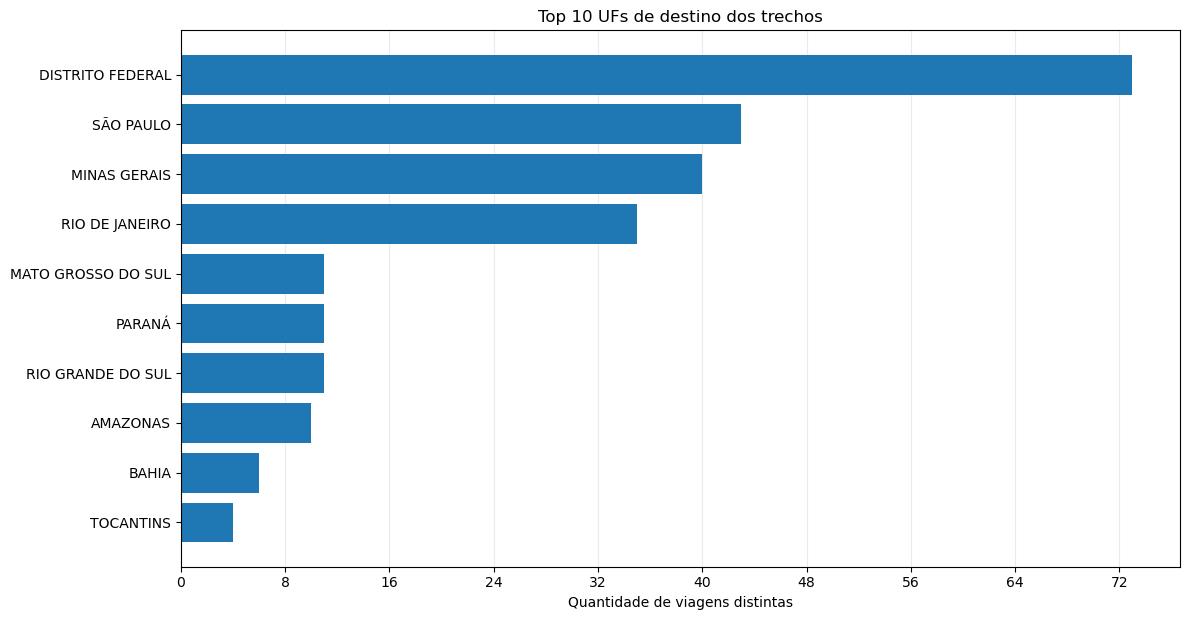

In [6]:
query = """
    SELECT
        UPPER(BTRIM(destino_uf)) AS uf_destino, -- Padroniza a UF registrada.
        COUNT(DISTINCT id_viagem) AS qtd_viagens -- Conta viagens distintas por UF.
    FROM silver_trajetos                        -- Uma linha por trecho.
    WHERE NULLIF(BTRIM(destino_uf), '') IS NOT NULL -- Exclui UFs vazias ou nulas.
    GROUP BY 1                                  -- Agrupa pela UF padronizada.
    ORDER BY qtd_viagens DESC, uf_destino        -- Ordena do maior para o menor.
    LIMIT 10;                                   -- Seleciona os dez primeiros.
"""

# Recupera os destinos mais frequentes.
df_destinos = consultar(query)
display(df_destinos)

# Visualiza o ranking de UFs de destino.
grafico_ranking(df_destinos, "uf_destino", "qtd_viagens",
                "Top 10 UFs de destino dos trechos", "Quantidade de viagens distintas")